# 04 · Maker Strategies
Can liquidation features improve hypothetical maker trade selection at comparable clipped turnover?

Original maker experiments use Binance trades/BBO and both liquidation feeds. Training is December–January;
February is repeatedly inspected validation. Tables are frozen results over all eligible raw trades, not the fit sample.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'pyproject.toml').exists())
sys.path.insert(0, str(ROOT/'src'))
sys.path.insert(0, str(ROOT))
from research_paths import artifact_dir
import research_report as report
report.style()
def show(fig, name):
    path=ROOT/'artifacts/figures'/name
    fig.savefig(path, dpi=150)
    display(Image(filename=str(path)))
    plt.close(fig)

## Labels, weights and baselines
For taker sign `s`, trade price `p` and backward-as-of midpoint `m(t+h)`:
`y = −s × (m(t+h) − p) / p × 10000 + 0.5` bps; `w = min(p × amount, 100000)`.
A quote exactly at the target timestamp is allowed; targets outside global BBO bounds are excluded.
The filter is `0 = keep, 1 = filter`. Score is weighted `PnL_kept − PnL_all`.

E0 keeps all eligible trades. E0_random is a separate budget-matched control.
E1 is the initial 5-second reconstruction; E1_60 is the corrected 60-second signed-flow rule;
E1_60_strength additionally ranks eligible trades by prior-boundary absolute net liquidation notional.
The latter is the selected default submission, a source-informed extension with no claim of baseline authorship.

In [2]:
display(report.table('maker','experiment_matrix.csv'))
display(report.table('maker','baseline_summary.csv').query("split=='validation' and model=='E0'")[
    ['symbol','tau','pnl_all','score','kept_turnover_per_day']])

,model,status
0,E0,full exact keep-all
1,E1_60,documented60s rule reconstructed; raw-price cl...
2,E1_60_strength,source-informed fixed flow ranking; additional...
3,E2,new Ridge; historical fitted artifact unavailable
4,E3,new LightGBM; historical V4 fitted artifact un...
5,E4,same LightGBM without liquidation features
6,E5,E3 plus chronological OOF LR probabilities
7,E6,E3 plus observable AS-inspired risk features
8,E7,E3 plus both feature sets
9,E8,not identifiable: no own inventory/queue/fills/k


,symbol,tau,pnl_all,score,kept_turnover_per_day
3,btcusdt,30,-0.187706,0.000000,"14,653,984,313.472986"
4,btcusdt,120,-0.174254,0.000000,"14,653,862,723.983829"
5,btcusdt,300,-0.155612,0.000000,"14,653,646,259.324030"
9,combined,30,-0.046409,0.000000,"27,168,831,591.393929"
10,combined,120,-0.032564,0.000000,"27,168,485,482.101299"
11,combined,300,0.024532,0.000000,"27,168,026,977.062092"
15,ethusdt,30,0.119039,0.000000,"12,514,847,277.920942"
16,ethusdt,120,0.133346,0.000000,"12,514,622,758.117474"
17,ethusdt,300,0.235471,0.000000,"12,514,380,717.738058"


## Ridge, LightGBM and loss
E2 is standardized Ridge (alpha=100). E3 is a fixed 32-tree LightGBM regressor; E4 removes liquidation features
and alignment. E5 adds chronological Logistic Regression probabilities; E6 adds six observable A–S risk proxies;
E7 adds both. E8 is not identified: inventory, own fills, queue state and execution intensity are unavailable.

Regression fits a deterministic 1/16 sample of feature-equivalence groups, with summed clipped-notional weights
corrected by 16 and normalized to mean one. The target is the group's weighted mean markout, without clipping.
Effective training starts December 22; `second + 301 < boundary` is enforced.
Ridge minimizes weighted squared error plus its L2 penalty; LightGBM uses weighted squared error.
Official Score is evaluated separately.

In [3]:
spec=json.loads((artifact_dir('maker')/'experiment_specification.json').read_text())
display(pd.Series(spec['LGBMRegressor'],name='fixed parameter').to_frame())
display(report.primary(['E1_60_strength','E2','E3','E4','E5','E6','E7'])[
    ['model','tau','score','pnl_all','pnl_kept','pnl_filtered','kept_turnover_per_day']])

,fixed parameter
objective,regression
n_estimators,32
num_leaves,15
max_depth,5
learning_rate,0.050000
min_child_samples,200
reg_lambda,1.000000
n_jobs,4


,model,tau,score,pnl_all,pnl_kept,pnl_filtered,kept_turnover_per_day
697,E1_60_strength,30,9.162323,-0.046409,9.115914,-0.131502,"250,000,235.444371"
705,E1_60_strength,120,18.893918,-0.032564,18.861354,-0.208038,"250,000,235.444371"
713,E1_60_strength,300,15.585496,0.024532,15.610028,-0.120217,"250,000,235.444371"
175,E2,30,16.078705,-0.046409,16.032296,-0.195735,"250,000,307.616060"
183,E2,120,13.616301,-0.032564,13.583737,-0.159023,"250,000,133.671020"
191,E2,300,13.991484,0.024532,14.016017,-0.105413,"250,000,180.976760"
247,E3,30,5.148496,-0.046409,5.102086,-0.094224,"250,000,082.296406"
255,E3,120,6.735727,-0.032564,6.703163,-0.095121,"250,000,505.058242"
263,E3,300,5.531530,0.024532,5.556062,-0.026842,"250,000,074.445579"
319,E4,30,17.811140,-0.046409,17.764731,-0.211826,"250,002,415.884847"


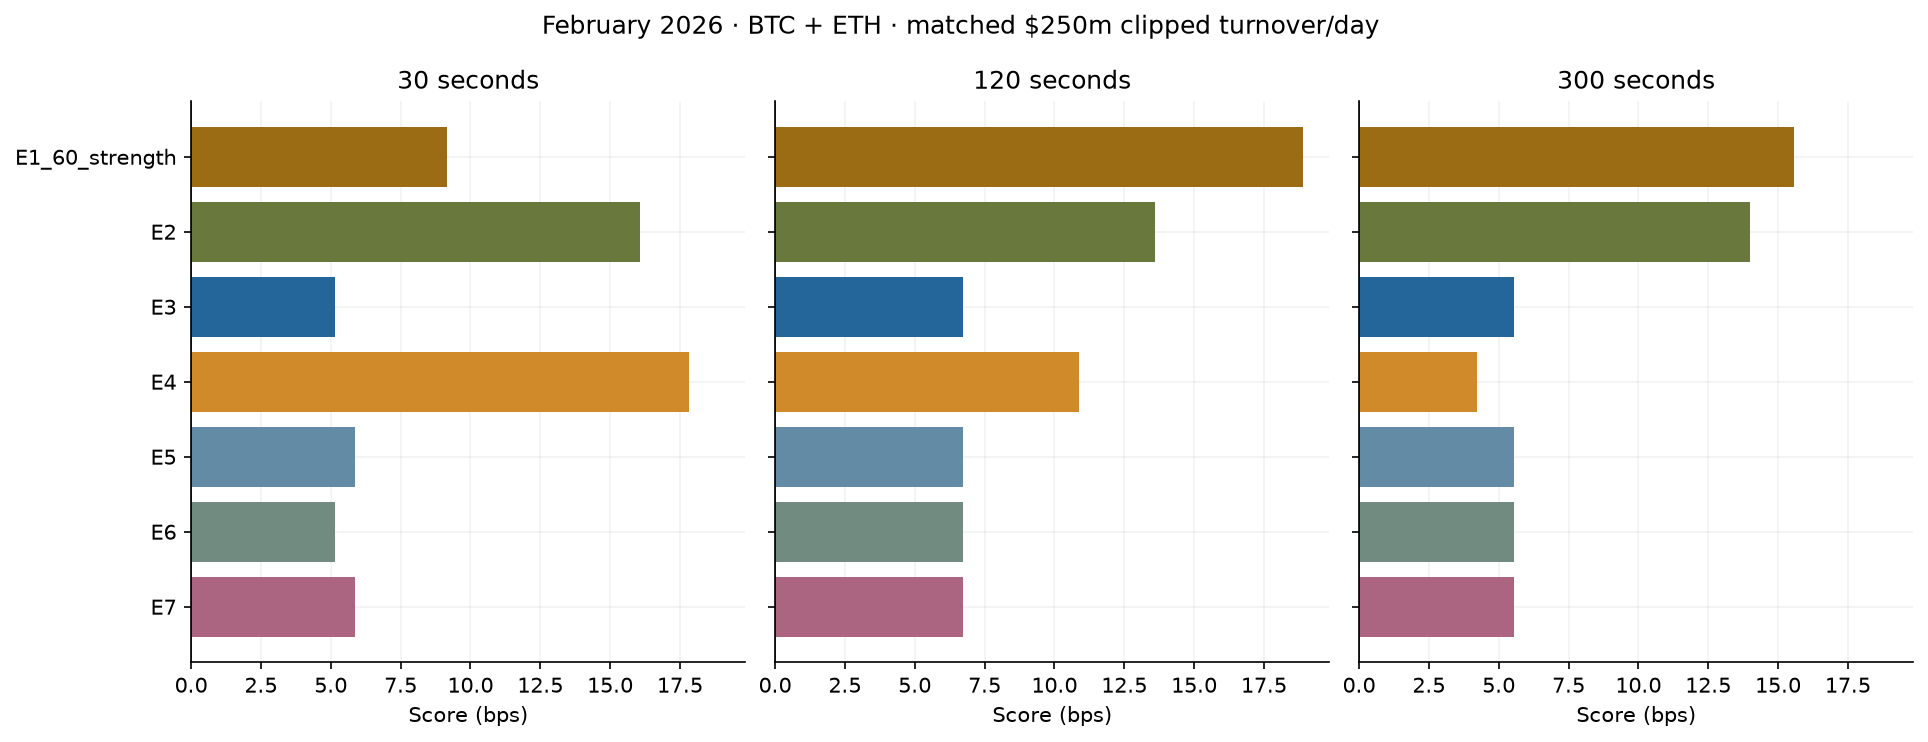

In [4]:
show(report.score_figure(['E1_60_strength','E2','E3','E4','E5','E6','E7']),'maker_scores.png')

## Controlled liquidation and stacking ablations
E3−E4 isolates the presence of liquidation features under the fixed setup, not a fully optimized model-family comparison.
February E3−E4 Scores are −12.662645, −4.126121 and +1.319553 bps at 30/120/300 seconds.
The 5-day block intervals in the expanded retrospective family include zero at all three horizons.

,block_days,scope,tau,model,comparator,delta_score,ci_low,ci_high,finite_bootstrap_fraction,confidence_level,interpretation
120,5,combined,30,E5,E3,0.728006,-3.159587,4.143341,1.000000,0.997917,source-informed expanded family; retrospective...
123,5,combined,30,E6,E3,0.000000,0.000000,0.000000,1.000000,0.997917,source-informed expanded family; retrospective...
124,5,combined,30,E3,E4,-12.662645,-27.291954,1.062176,1.000000,0.997917,source-informed expanded family; retrospective...
128,5,combined,120,E5,E3,0.000000,0.000000,0.000000,1.000000,0.997917,source-informed expanded family; retrospective...
131,5,combined,120,E6,E3,0.000000,0.000000,0.000000,1.000000,0.997917,source-informed expanded family; retrospective...
132,5,combined,120,E3,E4,-4.126121,-11.958412,7.033115,1.000000,0.997917,source-informed expanded family; retrospective...
136,5,combined,300,E5,E3,0.000000,0.000000,0.000000,1.000000,0.997917,source-informed expanded family; retrospective...
139,5,combined,300,E6,E3,0.000000,0.000000,0.000000,1.000000,0.997917,source-informed expanded family; retrospective...
140,5,combined,300,E3,E4,1.319553,-4.975836,7.374374,1.000000,0.997917,source-informed expanded family; retrospective...


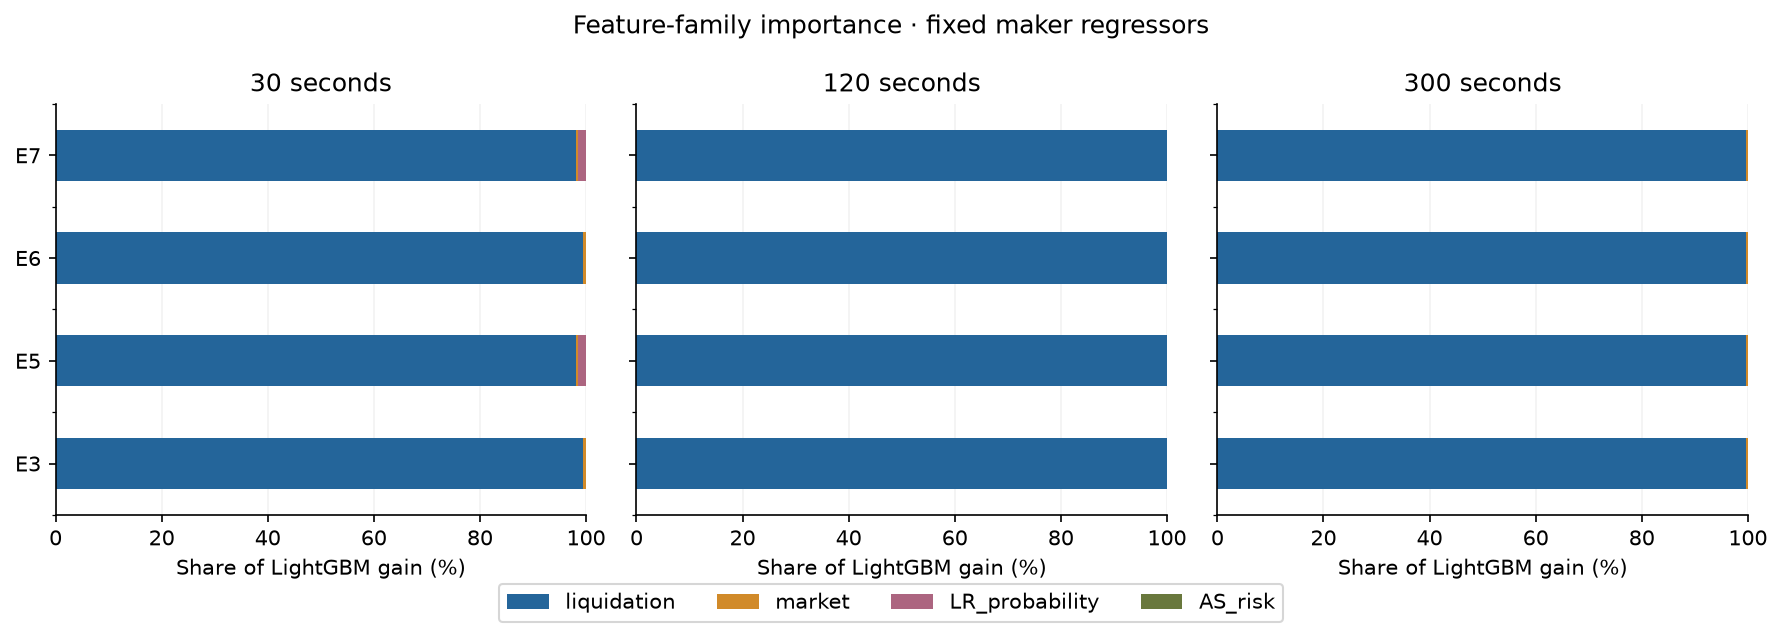

In [5]:
paired=report.table('maker','expanded_paired_comparisons.csv').query("scope=='combined' and block_days==5")
display(paired.query("(model=='E3' and comparator=='E4') or (model=='E5' and comparator=='E3') or (model=='E6' and comparator=='E3')"))
show(report.family_importance_figure(),'feature_families.png')

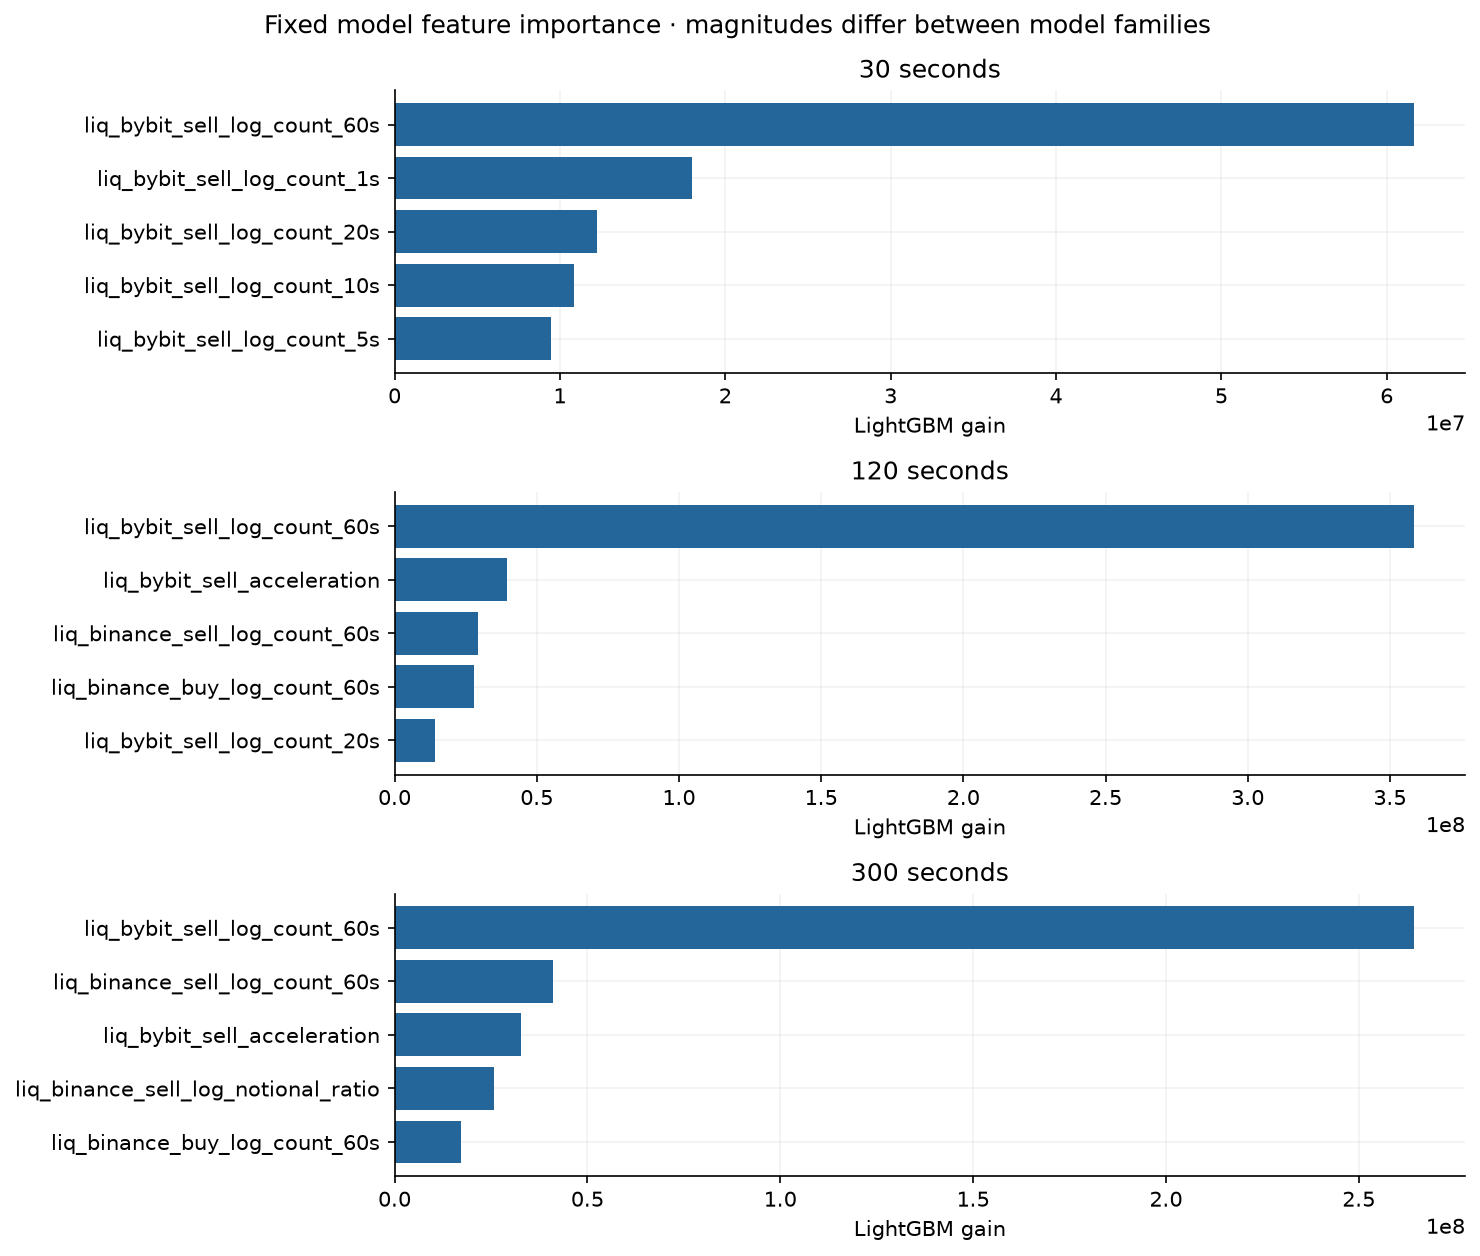

In [6]:
show(report.top_importance_figure(),'lightgbm_importance.png')

Liquidation features account for almost all E3 gain, yet removing them improves the short-horizon point Score.
Split gain is model usage, not causal evidence or an economic attribution. Logistic additions change the 30-second
Score by +0.728006 bps, without a positive adjusted paired interval; 120/300-second predictions are unchanged.
A–S proxies have zero split gain in this setup, and E6 equals E3 while E7 equals E5.

## Inference contract
The default rule uses the published fixed thresholds and needs no fitted model.
E7/CatBoost weights are intentionally withheld pending clarification of upstream dataset rights.
Their preserved interfaces use the documented keep-all fallback when a model is absent;
that fallback must not be described as a successful learned-model run.

In [7]:
from submission import signal
sample=ROOT/'data/sample'
tr=pd.read_csv(sample/'binance_trades/perp_btcusdt.csv')
bb=pd.read_csv(sample/'binance_booktickers/perp_btcusdt.csv')
bn=pd.read_csv(sample/'binance_liquidations/perp_btcusdt.csv')
by=pd.read_csv(sample/'bybit_liquidations/btcusdt.csv')
filters=signal(tr,bb,bn,by)
assert set(filters)=={30,120,300}
display(pd.DataFrame([{'horizon_s':h,'synthetic_rows':len(v),'synthetic_kept_rows':int((v==0).sum())}
                      for h,v in filters.items()]))

,horizon_s,synthetic_rows,synthetic_kept_rows
0,30,1801,269
1,120,1801,269
2,300,1801,269


## Conclusion
Fixed regressors and ablations are implemented, but these results do not show a robust incremental advantage from
LR stacking or A–S proxies. Ridge/E4 lead at 30 seconds; the flow-strength rule has higher 120/300-second point Scores.
Independent evaluation is still needed before selecting a strategy prospectively.